# ARGus v2: Random Forest con k = 6 y Random Undersampling (solo negativos)

Protocolo de la reunión del 18-oct:
1. Submuestrear **solo los negativos** (Random Undersampling) dentro del entrenamiento.
2. Tomar **todos los positivos** del entrenamiento.
3. Entrenar el Random Forest (k = 6).
4. Evaluar en un **test separado por gen** (distribución natural, sin balancear).
5. Guardar el modelo (joblib).
6. Evaluar el modelo guardado en los **1k + 1k genes** y comparar con ARGus v1, DeepARG y ARGNet.

**Importante (fuga de datos):** los 2000 genes del 1k+1k se **excluyen del entrenamiento y del test**.
Si no, el modelo ya los habría visto y la comparación saldría inflada. La celda 2 lo verifica con un
`assert`: si no localiza los 2000, se detiene en lugar de entrenar con fuga.

---

## Fragmentación: regla de la asesora (reunión del 5-nov)

Antes los fragmentos se **rellenaban con ceros** hasta 500 pb. Eso tenía un defecto grave: un gen de
504 pb dejaba un último fragmento de **4 bases reales + 496 ceros**. El vector de k-meros se calcula
solo con las ventanas de ACGT válidas, y con 4 bases no hay ninguna ventana de 6 → el vector salía
**todo en cero**, y ante un vector de ceros el bosque siempre responde lo mismo (p = 0.7136), o sea
**positivo automático**. Así se colaban falsos positivos.

La regla nueva, tal como la indicó la asesora:

* cortar en bloques de 500 pb;
* el resto final se **conserva con su largo real, sin rellenar**, si tiene **≥ 150 pb**;
* si tiene **menos de 150 pb se descarta**;
* **nunca se usa padding**, así que los fragmentos miden entre 150 y 500 pb.

Y se aplica en **los dos lados**: al armar el entrenamiento (celda 2b) y al predecir sobre genes
completos (celda 8). Si solo se corrigiera la predicción, el modelo vería en inferencia una
distribución de fragmentos distinta a la que vio al entrenar.

Un gen más corto que 150 pb no produce ningún fragmento: queda **no evaluable**, y se reporta
aparte en lugar de contarlo como negativo (en la GUI sale como `No evaluable`).

El mismo cuaderno sirve para los sets de 90 % y 85 %: solo cambia `POSITIVOS_FILTRO` en la celda 1.

In [5]:
# ============ CELDA 1: configuración ============
import re, time, json, joblib
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix)

# --- raíz del proyecto: se detecta subiendo desde donde está el cuaderno ---
RAIZ = None
for cand in [Path.cwd(), *Path.cwd().parents]:
    if (cand / "data" / "interim").is_dir():
        RAIZ = cand
        break
if RAIZ is None:
    # el cuaderno está fuera del proyecto: pon la ruta a mano y vuelve a correr la celda
    RAIZ = Path.home() / "Proyecto_Residencias"
INTERIM = RAIZ / "data" / "interim"
print("raíz del proyecto:", RAIZ)
assert INTERIM.is_dir(), f"No existe {INTERIM}. Ajusta RAIZ a mano en esta celda."

DATASET_FRAG  = INTERIM / "dataset_fragmentado_500.tsv"       # id / lectura / etiqueta
DATASET_GENES = INTERIM / "dataset_etiquetado_completo.tsv"   # un gen por fila (1a col = id)
SET_1K1K      = INTERIM / "muestra_genes_labels.tsv"          # los 2000 genes de comparación
FASTA_1K1K    = INTERIM / "muestra_genes_completos.fasta"

# --- qué corrida es ---
# id95 (el set tal cual):     POSITIVOS_FILTRO = None
# id90 / id85 (set filtrado): POSITIVOS_FILTRO = INTERIM / "positivos_id90.fasta"
POSITIVOS_FILTRO = None
# "_v2" = con la regla de fragmentación nueva.
# CUIDADO: con esta etiqueta la celda 7 SOBRESCRIBE argus_rf_k6_id95_v2.joblib, que es el
# que la GUI está usando. Si quieres conservar el actual, cambia a "id95_v2_nb".
ETIQUETA_CORRIDA = "id95_v2"
if POSITIVOS_FILTRO is not None:
    assert Path(POSITIVOS_FILTRO).exists(), f"No existe el FASTA del filtro: {POSITIVOS_FILTRO}"

K       = 6        # indicación de la asesora
VENTANA = 500      # tamaño del bloque
MIN_PB  = 150      # mínimo de bases REALES por fragmento (regla de la asesora)
SEED      = 42
FRAC_TEST = 0.10
N_ARBOLES = 200

SALIDA = RAIZ / "data" / "models"; SALIDA.mkdir(parents=True, exist_ok=True)
for p in (DATASET_FRAG, DATASET_GENES, SET_1K1K, FASTA_1K1K):
    assert p.exists(), f"Falta el archivo: {p}"

print(f"K = {K} | columnas por fragmento: {4**K} | ventana = {VENTANA} | MIN_PB = {MIN_PB}")
print("corrida:", ETIQUETA_CORRIDA, "| filtro de positivos:", POSITIVOS_FILTRO)

raíz del proyecto: /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias
K = 6 | columnas por fragmento: 4096 | ventana = 500 | MIN_PB = 150
corrida: id95_v2 | filtro de positivos: None


In [6]:
# ============ CELDA 2: cargar fragmentos, asignar gen y excluir los 2000 genes ============
frag = pd.read_csv(DATASET_FRAG, sep="\t")
print(frag.shape); print(frag.head(3))

# detectar columnas por contenido (no por nombre)
col_lab = next(c for c in frag.columns if set(frag[c].dropna().unique()) <= {0, 1})
# la secuencia es la columna de texto más larga; se excluyen las numéricas
# (no se usa dtype == object porque pandas 3 marca el texto como 'str', no 'object')
_texto = [c for c in frag.columns if not pd.api.types.is_numeric_dtype(frag[c])]
col_seq = max(_texto, key=lambda c: frag[c].astype(str).str.len().mean())
col_id  = frag.columns[0]
print("id:", col_id, "| secuencia:", col_seq, "| etiqueta:", col_lab)

genes_all = pd.read_csv(DATASET_GENES, sep="\t")
ids_gen = set(genes_all.iloc[:, 0].astype(str))

# --- de qué gen viene cada fragmento ---
# El id de fragmento es "<id_del_gen>__fragN", así que el gen se obtiene quitando ESE sufijo
# y nada más.
#
# OJO: la versión anterior de esta celda usaba una función gen_de() que iba recortando
# sufijos (_frag3, |3, _3, .1 ...) hasta dar con un id existente. Eso mutilaba los ids que
# traen guiones, puntos o pipes (casi todos los de CARD y AMRFinderPlus) y dejaba 63,415
# negativos sin gen identificado. Peor: al no identificar el gen, esos fragmentos tampoco
# se podían excluir del 1k+1k ni agrupar bien en la partición. Por eso aquella corrida se
# descartó.
frag["gen"] = frag[col_id].astype(str).str.replace(r"__frag\d+$", "", regex=True)

sin_match = int((~frag["gen"].isin(ids_gen)).sum())
print(f"fragmentos cuyo gen NO está en la tabla de genes: {sin_match:,} de {len(frag):,}")
if sin_match:
    print("  ejemplos:", frag.loc[~frag['gen'].isin(ids_gen), col_id].head(3).tolist())
print(frag[[col_id, "gen"]].sample(5, random_state=1).to_string(index=False))

# --- excluir los 2000 genes del 1k+1k (esto evita la fuga) ---
lab1k = pd.read_csv(SET_1K1K, sep="\t")
ids_1k = set(lab1k.iloc[:, 0].astype(str))
genes_frag = set(frag["gen"])
hallados = len(ids_1k & genes_frag)
print(f"\ngenes del 1k+1k localizados en el dataset: {hallados} de {len(ids_1k)}")
assert hallados == len(ids_1k), (
    "No se localizaron TODOS los genes del 1k+1k. Si no se localizan no se excluyen, "
    "y entonces el modelo entrenaría con los mismos genes con los que se evalúa (fuga). "
    f"Revisa el formato de {col_id}: se espera '<gen>__fragN'.")

mask_1k = frag["gen"].isin(ids_1k)
print(f"fragmentos del 1k+1k (se excluyen): {mask_1k.sum():,}")
pool = frag[~mask_1k].reset_index(drop=True)
assert not (set(pool["gen"]) & ids_1k), "FUGA: quedó algún gen del 1k+1k en el pool"

# --- filtro opcional de positivos (90 % / 85 %) ---
if POSITIVOS_FILTRO is not None:
    ids_ok = {l[1:].split()[0] for l in open(POSITIVOS_FILTRO) if l.startswith(">")}
    quitar = (pool[col_lab] == 1) & (~pool["gen"].isin(ids_ok))
    print("positivos fuera del set filtrado:", int(quitar.sum()))
    pool = pool[~quitar].reset_index(drop=True)

print(pool[col_lab].value_counts().rename({0: "neg (frag)", 1: "pos (frag)"}))

(72874, 3)
                                                  id  \
0  CARD|gb|AF028812.1|+|392-887|ARO:3002867|dfrF_...   
1  CARD|gb|AY234334.1|+|0-846|ARO:3000600|Erm(34)...   
2  CARD|gb|AY234334.1|+|0-846|ARO:3000600|Erm(34)...   

                                             lectura  etiqueta  
0  ATGATAGGTTTGATTGTTGCGAGGTCAAAGAATAATGTTATAGGCA...         1  
1  ATGACGAAAAAAATGAACAAGTATAATGGGAAAAAACTTAGCCGTG...         1  
2  TGACATCCACTATGAAAGGGGAATTTCCAGAAGTTCATTTTCGCCG...         1  
id: id | secuencia: lectura | etiqueta: etiqueta
fragmentos cuyo gen NO está en la tabla de genes: 63,415 de 72,874
  ejemplos: ['GCF_000005845.2|NC_000913.3_2__frag0', 'GCF_000005845.2|NC_000913.3_2__frag1', 'GCF_000005845.2|NC_000913.3_2__frag2']
                                             id                                      gen
        GCF_000008865.2|NC_002695.2_4840__frag0         GCF_000008865.2|NC_002695.2_4840
        GCF_000005845.2|NC_000913.3_1377__frag2         GCF_000005845.2|NC_00

In [7]:
# ============ CELDA 2b: regla de fragmentación de la asesora, aplicada al ENTRENAMIENTO ============
# El TSV guarda los fragmentos YA rellenados con ceros hasta 500 pb. Aquí se deshace ese
# relleno y se aplica la regla nueva, para que el modelo entrene con la misma clase de
# fragmentos que va a ver en la celda 8 y en la GUI:
#
#   * se quitan los ceros  -> queda el largo real
#   * se descarta el fragmento si le quedan menos de MIN_PB bases reales
#   * no se vuelve a rellenar -> fragmentos de largo variable entre MIN_PB y VENTANA
#
# Nota importante: quitar los ceros NO cambia el vector de k-meros de los fragmentos que se
# quedan (vector_kmer ignora toda ventana que toque un carácter que no sea ACGT y normaliza
# por las ventanas válidas). Lo que cambia de verdad es el DESCARTE de los fragmentos cortos,
# que son los que daban vector todo-ceros y salían positivos por defecto.

antes = len(pool)
seq_real = pool[col_seq].astype(str).str.upper().str.replace("0", "", regex=False)
pb_reales = seq_real.str.len()

cortos = pb_reales < MIN_PB
print(f"fragmentos con menos de {MIN_PB} pb reales (se descartan): {int(cortos.sum()):,}")
if cortos.any():
    print(pool.loc[cortos, col_lab].value_counts()
          .rename({0: "  de ellos negativos", 1: "  de ellos positivos"}).to_string())
    print(f"  largo real de los descartados: min {int(pb_reales[cortos].min())} pb, "
          f"max {int(pb_reales[cortos].max())} pb")

pool = pool.loc[~cortos].reset_index(drop=True)
pool[col_seq] = seq_real.loc[~cortos].reset_index(drop=True)
print(f"\nfragmentos: {antes:,} -> {len(pool):,}")

# genes que se quedaron sin ningún fragmento
genes_antes = set(frag.loc[~mask_1k, "gen"])
genes_ahora = set(pool["gen"])
perdidos = genes_antes - genes_ahora
print(f"genes que quedaron SIN fragmentos (no evaluables): {len(perdidos):,} "
      f"de {len(genes_antes):,}")

# cómo quedó la distribución de largos
L = pool[col_seq].str.len()
print(f"\nlargo de fragmento: min {int(L.min())} | mediana {int(L.median())} | max {int(L.max())} pb")
print("  (debe estar entre", MIN_PB, "y", VENTANA, "-- sin ceros en ninguno)")
assert L.min() >= MIN_PB and L.max() <= VENTANA, "quedó algún fragmento fuera del rango"
assert not pool[col_seq].str.contains("0").any(), "quedó relleno en algún fragmento"
print(pool[col_lab].value_counts().rename({0: "neg (frag)", 1: "pos (frag)"}).to_string())

fragmentos con menos de 150 pb reales (se descartan): 7,662
etiqueta
de ellos negativos    6646
de ellos positivos    1016
  largo real de los descartados: min 1 pb, max 149 pb

fragmentos: 68,207 -> 60,545
genes que quedaron SIN fragmentos (no evaluables): 422 de 28,741

largo de fragmento: min 150 | mediana 500 | max 500 pb
  (debe estar entre 150 y 500 -- sin ceros en ninguno)
etiqueta
neg (frag)    54332
pos (frag)     6213


In [8]:
# ============ CELDA 3: k-mers rápidos (vectorizado) y fragmentación ============
LUT = np.full(256, 4, dtype=np.int8)
for i, b in enumerate(b"ACGT"): LUT[b] = i
POT = (4 ** np.arange(K - 1, -1, -1)).astype(np.int64)

def vector_kmer(seq):
    # frecuencia relativa de los 4^K k-mers; toda ventana que toque un carácter que no sea
    # ACGT (una N, o un '0' de relleno) se ignora, y se normaliza por las ventanas válidas
    a = LUT[np.frombuffer(seq.upper().encode("ascii", "replace"), dtype=np.uint8)]
    n = len(a) - K + 1
    out = np.zeros(4 ** K, dtype=np.float32)
    if n <= 0: return out
    win = np.lib.stride_tricks.sliding_window_view(a, K)
    ok = (win < 4).all(axis=1)
    if not ok.any(): return out
    idx = (win[ok].astype(np.int64) * POT).sum(axis=1)
    out += np.bincount(idx, minlength=4 ** K).astype(np.float32)
    return out / out.sum()

def matriz(seqs):
    X = np.empty((len(seqs), 4 ** K), dtype=np.float32)
    for i, s in enumerate(seqs): X[i] = vector_kmer(s)
    return X

def fragmentar(seq, ventana=VENTANA, min_pb=MIN_PB):
    """
    Regla de la asesora. Bloques de `ventana` pb; el resto final se conserva con su largo
    real SIN rellenar si alcanza `min_pb` bases, y se descarta si no. Nunca mete ceros.
    Un gen más corto que min_pb devuelve [] -> gen no evaluable.
    """
    seq = seq.upper()
    L = len(seq)
    if L < ventana:
        return [seq] if L >= min_pb else []
    n = L // ventana
    fr = [seq[i * ventana:(i + 1) * ventana] for i in range(n)]
    r = L - n * ventana
    if r >= min_pb:
        fr.append(seq[n * ventana:])        # tal cual, sin rellenar
    return fr

# --- prueba 1: el relleno NO cambia el vector de k-meros ---
#     por eso quitar los ceros es inocuo y lo que importa es descartar los cortos
base = "ACGT" * 50                                   # 200 pb reales
v_sin  = vector_kmer(base)
v_con  = vector_kmer(base + "0" * 300)               # las mismas 200 pb + 300 ceros
print("200 pb solas vs 200 pb + 300 ceros -> vectores idénticos:",
      np.array_equal(v_sin, v_con), "| suma =", round(float(v_sin.sum()), 6))

# --- prueba 2: un fragmento de pocas bases da vector TODO EN CERO (el bug viejo) ---
print("vector de un fragmento de 4 bases + relleno -> todo en cero:",
      not vector_kmer("ACGT" + "0" * 496).any())

# --- prueba 3: la fragmentación nueva, en varios largos ---
for L in (93, 150, 499, 504, 650, 1000, 1200, 1503):
    fr = fragmentar("A" * L)
    print(f"  gen de {L:>4} pb -> {len(fr)} fragmento(s) de {[len(f) for f in fr]}")

200 pb solas vs 200 pb + 300 ceros -> vectores idénticos: True | suma = 1.0
vector de un fragmento de 4 bases + relleno -> todo en cero: True
  gen de   93 pb -> 0 fragmento(s) de []
  gen de  150 pb -> 1 fragmento(s) de [150]
  gen de  499 pb -> 1 fragmento(s) de [499]
  gen de  504 pb -> 1 fragmento(s) de [500]
  gen de  650 pb -> 2 fragmento(s) de [500, 150]
  gen de 1000 pb -> 2 fragmento(s) de [500, 500]
  gen de 1200 pb -> 3 fragmento(s) de [500, 500, 200]
  gen de 1503 pb -> 3 fragmento(s) de [500, 500, 500]


In [9]:
# ============ CELDA 4: partición por gen (train / test) y Random Undersampling SOLO en train ============
y_all = pool[col_lab].values
g_all = pool["gen"].values

# Un pliegue de StratifiedGroupKFold(10) = 10 % de los genes para test, sin que un gen quede en ambos lados
sgkf = StratifiedGroupKFold(n_splits=int(round(1 / FRAC_TEST)), shuffle=True, random_state=SEED)
tr, te = next(sgkf.split(np.zeros(len(y_all)), y_all, g_all))
assert not set(g_all[tr]) & set(g_all[te]), "FUGA: un gen aparece en train y test"

rng = np.random.default_rng(SEED)
pos = tr[y_all[tr] == 1]                                   # TODOS los positivos del train
neg = tr[y_all[tr] == 0]
neg_ds = rng.choice(neg, size=len(pos), replace=False)     # Random Undersampling (solo negativos)
tr_bal = np.concatenate([pos, neg_ds]); rng.shuffle(tr_bal)

print(f"train original : pos={len(pos):,}  neg={len(neg):,}  (razón {len(neg)/len(pos):.1f}:1)")
print(f"train balanceado: pos={len(pos):,}  neg={len(neg_ds):,}")
print(f"test (natural) : pos={(y_all[te]==1).sum():,}  neg={(y_all[te]==0).sum():,}")
print(f"genes: train {len(set(g_all[tr])):,} | test {len(set(g_all[te])):,}")

train original : pos=5,592  neg=48,898  (razón 8.7:1)
train balanceado: pos=5,592  neg=5,592
test (natural) : pos=621  neg=5,434
genes: train 25,487 | test 2,832


In [10]:
# ============ CELDA 5: features (solo de lo necesario -> ahorra RAM) y entrenamiento ============
t0 = time.time()
seqs = pool[col_seq].astype(str).values
X_tr = matriz(seqs[tr_bal]); y_tr = y_all[tr_bal]
print("X_train:", X_tr.shape, f"{X_tr.nbytes/1e9:.2f} GB", f"({time.time()-t0:.0f}s)")

rf = RandomForestClassifier(n_estimators=N_ARBOLES, n_jobs=-1, random_state=SEED)
rf.fit(X_tr, y_tr)
print(f"RF entrenado en {time.time()-t0:.0f}s")

X_train: (11184, 4096) 0.18 GB (1s)
RF entrenado en 7s


In [11]:
# ============ CELDA 6: evaluación en el TEST (distribución natural) ============
X_te = matriz(seqs[te]); y_te = y_all[te]
p_te = rf.predict_proba(X_te)[:, 1]; pred_te = (p_te >= 0.5).astype(int)

def metricas(y, pred, p=None):
    d = dict(recall=recall_score(y, pred), precision=precision_score(y, pred, zero_division=0),
             f1=f1_score(y, pred))
    if p is not None: d["auc"] = roc_auc_score(y, p)
    return d

m_frag = metricas(y_te, pred_te, p_te)
print("== FRAGMENTO ==", {k: round(v, 3) for k, v in m_frag.items()})
print(confusion_matrix(y_te, pred_te))

# nivel gen: un gen es ARG si ALGÚN fragmento lo es (misma regla que en la comparación)
df_te = pd.DataFrame({"gen": g_all[te], "y": y_te, "pred": pred_te, "p": p_te})
gg = df_te.groupby("gen").agg(y=("y", "max"), pred=("pred", "max"), p=("p", "max"))
m_gen = metricas(gg.y, gg.pred, gg.p)
print("== GEN (any) ==", {k: round(v, 3) for k, v in m_gen.items()}, "| genes test:", len(gg))

== FRAGMENTO == {'recall': 0.787, 'precision': 0.353, 'f1': 0.487, 'auc': 0.887}
[[4536  898]
 [ 132  489]]
== GEN (any) == {'recall': 0.907, 'precision': 0.298, 'f1': 0.448, 'auc': 0.908} | genes test: 2832


In [12]:
# ============ CELDA 7: guardar el modelo ============
ruta_modelo = SALIDA / f"argus_rf_k{K}_{ETIQUETA_CORRIDA}.joblib"
joblib.dump({"modelo": rf,
             "K": K,
             "ventana": VENTANA,
             # --- fragmentación: regla de la asesora, 5-nov ---
             "relleno": "ninguno",
             "min_pb": MIN_PB,
             "fragmentacion": (f"bloques de {VENTANA} pb; el resto final se conserva con su "
                               f"largo real sin rellenar si tiene >= {MIN_PB} pb, y se "
                               f"descarta si no. Un gen de < {MIN_PB} pb es no evaluable."),
             "regla_gen": "any",
             "umbral": 0.5,
             "semilla": SEED,
             "metricas_test_fragmento": m_frag,
             "metricas_test_gen": m_gen}, ruta_modelo, compress=3)
print("guardado:", ruta_modelo, f"{ruta_modelo.stat().st_size/1e6:.0f} MB")
print("\nLa GUI lee estos metadatos; 'min_pb' es el que debe coincidir con")
print("MIN_PB_FRAGMENTO en app/argus_gui.py.")

guardado: /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/models/argus_rf_k6_id95_v2.joblib 10 MB

La GUI lee estos metadatos; 'min_pb' es el que debe coincidir con
MIN_PB_FRAGMENTO en app/argus_gui.py.


## Comparación en los 1k + 1k
Se carga el modelo **guardado** (como lo hará la GUI) y se evalúa sobre los 2000 genes completos, que
el modelo nunca vio. La fragmentación es la misma regla de la celda 3, así que los genes de menos de
`MIN_PB` pb no producen fragmentos: se reportan como **no evaluables** y se dejan fuera de las
métricas, en lugar de contarlos como negativos.

In [13]:
# ============ CELDA 8: ARGus v2 sobre los 2000 genes (modelo cargado desde disco) ============
pk = joblib.load(ruta_modelo); rf2 = pk["modelo"]
print("metadatos del modelo:", {k: v for k, v in pk.items() if k != "modelo"
                                and not k.startswith("metricas")})

def leer_fasta(path):
    d, cur = {}, None
    for l in open(path, encoding="utf-8", errors="replace"):
        l = l.strip()
        if l.startswith(">"): cur = l[1:].split()[0]; d[cur] = []
        elif cur: d[cur].append(l)
    return {k: "".join(v) for k, v in d.items()}

fa = leer_fasta(FASTA_1K1K)
y_1k = dict(zip(lab1k.iloc[:, 0].astype(str), lab1k.iloc[:, 1].astype(int)))
ids = [i for i in fa if i in y_1k]
print("genes con secuencia y etiqueta:", len(ids), "de", len(y_1k))

# la fragmentación la toma de los metadatos del modelo, no de constantes sueltas
VENT_M = int(pk.get("ventana", VENTANA))
MINPB_M = int(pk.get("min_pb", MIN_PB))

filas, no_eval = [], []
for gid in ids:
    fr = fragmentar(fa[gid], VENT_M, MINPB_M)
    if not fr:                                  # gen más corto que MINPB_M
        no_eval.append((gid, y_1k[gid], len(fa[gid])))
        continue
    p = rf2.predict_proba(matriz(fr))[:, 1]
    filas.append((gid, y_1k[gid], int((p >= pk["umbral"]).any()), p.max(), len(fr)))

r1k = pd.DataFrame(filas, columns=["gen", "y", "pred", "p", "n_frag"])
print(f"\ngenes NO evaluables (< {MINPB_M} pb, fuera de las métricas): {len(no_eval)}")
if no_eval:
    ne = pd.DataFrame(no_eval, columns=["gen", "y", "pb"])
    print(ne.y.value_counts().rename({0: "  de ellos negativos", 1: "  de ellos positivos"}).to_string())
    print("  largos:", sorted(ne.pb)[:10], "..." if len(ne) > 10 else "")

m_v2 = metricas(r1k.y, r1k.pred, r1k.p)
print(f"\nARGus v2 (1k+1k, {len(r1k)} genes evaluados):",
      {k: round(v, 3) for k, v in m_v2.items()})
cm = confusion_matrix(r1k.y, r1k.pred)
print(cm)
print(f"  predichos como resistentes: {int(r1k.pred.sum()):,}  "
      f"(verdaderos positivos {int(cm[1,1])}, falsos positivos {int(cm[0,1])})")

metadatos del modelo: {'K': 6, 'ventana': 500, 'relleno': 'ninguno', 'min_pb': 150, 'fragmentacion': 'bloques de 500 pb; el resto final se conserva con su largo real sin rellenar si tiene >= 150 pb, y se descarta si no. Un gen de < 150 pb es no evaluable.', 'regla_gen': 'any', 'umbral': 0.5, 'semilla': 42}
genes con secuencia y etiqueta: 2000 de 2000

genes NO evaluables (< 150 pb, fuera de las métricas): 23
y
de ellos negativos    23
  largos: [93, 96, 96, 99, 105, 108, 111, 111, 114, 117] ...

ARGus v2 (1k+1k, 1977 genes evaluados): {'recall': 0.889, 'precision': 0.769, 'f1': 0.825, 'auc': 0.902}
[[710 267]
 [111 889]]
  predichos como resistentes: 1,156  (verdaderos positivos 889, falsos positivos 267)


In [16]:
# ============ CELDA 9: tabla comparativa (ARGus v1, ARGus v2, ARGNet, DeepARG) ============
# ARGus v1 = los números del gráfico anterior (OOF a nivel gen, k=4, 2000 genes)
ARGUS_V1 = dict(recall=0.893, precision=0.745, f1=0.813)

# ARGNet: archivo comparacion_genes_argnet.txt (col 2 = ARG / non-ARG)  -> ajusta rutas/columnas si difieren
# DeepARG: gen es ARG si su id aparece en .mapping.ARG (read_id = columna índice 3)
def baseline_argnet(path):
    t = pd.read_csv(path, sep="\t", header=None, comment="#")
    pred = (t.iloc[:, 2].astype(str).str.upper() == "ARG").astype(int)
    return dict(zip(t.iloc[:, 0].astype(str), pred))

def baseline_deeparg(path, ids):
    t = pd.read_csv(path, sep="\t", header=0)
    arg = set(t.iloc[:, 3].astype(str))
    return {i: int(i in arg) for i in ids}

tabla = {"ARGus v1 (k=4)": ARGUS_V1, f"ARGus v2 (k=6, undersampling, {ETIQUETA_CORRIDA})": m_v2}
try:
    ARGNET = Path.home() / "ARGNet" / "results" / "comparacion_argnet.txt"
    d = baseline_argnet(ARGNET)
    tabla["ARGNet"] = metricas(r1k.y, r1k.gen.map(lambda g: d.get(g, 0)))
except Exception as e: print("ARGNet: ajustar ruta/columnas ->", e)
try:
    DEEP = RAIZ / "results" / "deeparg_genes_id30.mapping.ARG"
    d = baseline_deeparg(DEEP, r1k.gen)
    tabla["DeepARG (id30)"] = metricas(r1k.y, r1k.gen.map(d))
except Exception as e: print("DeepARG: ajustar ruta/columnas ->", e)

res = pd.DataFrame(tabla).T[["recall", "precision", "f1"]].round(3)
print(res)
res.to_csv(SALIDA / f"comparacion_{ETIQUETA_CORRIDA}.csv")
print("guardado:", SALIDA / f"comparacion_{ETIQUETA_CORRIDA}.csv")

                                        recall  precision     f1
ARGus v1 (k=4)                           0.893      0.745  0.813
ARGus v2 (k=6, undersampling, id95_v2)   0.889      0.769  0.825
ARGNet                                   0.000      0.000  0.000
DeepARG (id30)                           0.720      0.978  0.829
guardado: /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/models/comparacion_id95_v2.csv


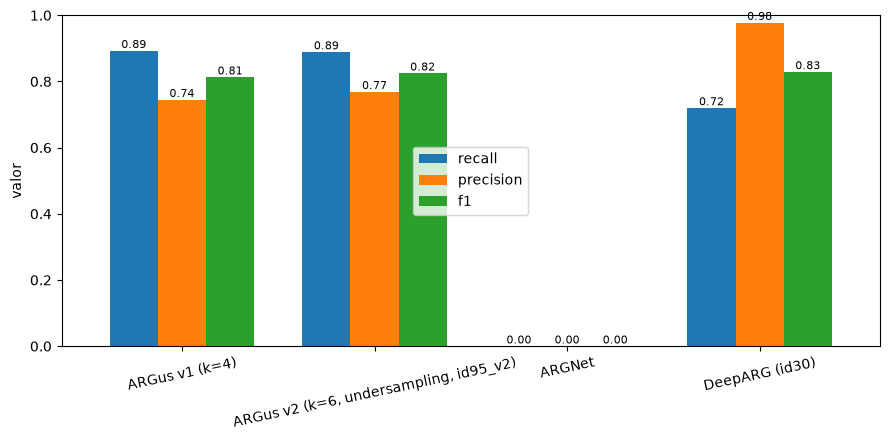

In [19]:
# ============ CELDA 10: gráfica (solo los 3 modelos + v1) ============
import matplotlib.pyplot as plt
ax = res.plot.bar(figsize=(9, 4.5), rot=12, width=0.75)
ax.set_ylim(0, 1); ax.set_ylabel("valor")

for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(SALIDA / f"comparacion_{ETIQUETA_CORRIDA}.png", dpi=200); plt.show()